In [1]:
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt
import torch.nn.functional as F

[codecarbon WARNING @ 13:14:49] Nvidia GPU detected but pynvml initialization failed. Please ensure NVIDIA drivers are properly installed.


In [2]:
TEXT_COL = "sentence"
LABEL_COL = "label"

SAMPLE_SIZE = 200
RANDOM_SEED = 42
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased",
]

In [3]:
csv = "financial_original.csv"
df = pd.read_csv(csv)
print(df.head())
print(df.columns)
print(df.shape)

                                            sentence  label
0  According to Gran , the company has no plans t...      1
1  Technopolis plans to develop in stages an area...      1
2  The international electronic industry company ...      0
3  With the new production plant the company woul...      2
4  According to the company 's updated strategy f...      2
Index(['sentence', 'label'], dtype='str')
(4846, 2)


In [4]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"[?|!|\'|\"|#]", "", text)
    text = re.sub(r"[.|,|)|(|\\|/]", " ", text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def load_and_clean_dataset(csv_file):
    df = pd.read_csv(csv_file)
    df = df[[TEXT_COL, LABEL_COL]].dropna().drop_duplicates().copy()

    df["clean_sentence"] = df[TEXT_COL].apply(clean_text)
    df["length"] = df["clean_sentence"].apply(len)

    print(df.head())
    print(df[LABEL_COL].value_counts())
    print(df.shape)

    return df

In [5]:
def add_length_quantile_groups(df, num_quantiles=100):
    df = df.copy()

    quantiles = df["length"].quantile(
        [i / num_quantiles for i in range(1, num_quantiles)]
    ).tolist()

    quantiles = np.unique(quantiles).tolist()

    bins = [df["length"].min()] + quantiles + [df["length"].max()]
    labels = [f"Q{i+1}" for i in range(len(bins) - 1)]

    df["quantiles"] = pd.cut(
        df["length"],
        bins=bins,
        labels=labels,
        include_lowest=True,
        duplicates="drop"
    )

    print(df["quantiles"].value_counts().sort_index())

    return df

In [7]:
def add_length_quantile_groups(df, num_quantiles=100):
    df = df.copy()

    quantiles = df["length"].quantile(
        [i / num_quantiles for i in range(1, num_quantiles)]
    ).tolist()

    quantiles = np.unique(quantiles).tolist()

    bins = [df["length"].min()] + quantiles + [df["length"].max()]
    labels = [f"Q{i+1}" for i in range(len(bins) - 1)]

    df["quantiles"] = pd.cut(
        df["length"],
        bins=bins,
        labels=labels,
        include_lowest=True,
        duplicates="drop"
    )

    print(df["quantiles"].value_counts().sort_index())

    return df

In [9]:
df = load_and_clean_dataset(csv)
df = add_length_quantile_groups(df)
print(df.head())
print(df.columns)
print(df.shape)

                                            sentence  label  \
0  According to Gran , the company has no plans t...      1   
1  Technopolis plans to develop in stages an area...      1   
2  The international electronic industry company ...      0   
3  With the new production plant the company woul...      2   
4  According to the company 's updated strategy f...      2   

                                      clean_sentence  length  
0  According to Gran the company has no plans to ...     121  
1  Technopolis plans to develop in stages an area...     186  
2  The international electronic industry company ...     224  
3  With the new production plant the company woul...     204  
4  According to the company s updated strategy fo...     198  
label
1    2873
2    1363
0     604
Name: count, dtype: int64
(4840, 4)
quantiles
Q1      51
Q2      46
Q3      55
Q4      43
Q5      47
        ..
Q96     41
Q97     49
Q98     50
Q99     48
Q100    46
Name: count, Length: 100, dtype: int64
 

In [10]:
def sample_from_length_groups(df, sample_size=200, num_quantiles=100, random_seed=42):
    n_samples = sample_size // num_quantiles

    sampled_df = (
        df.groupby("quantiles", group_keys=False)
        .apply(lambda x: x.sample(n=min(n_samples, len(x)), random_state=random_seed))
        .reset_index(drop=True)
    )

    print("Actual Sample Size:", len(sampled_df))
    print("Minimum Token Count:", sampled_df["clean_sentence"].str.split().apply(len).min())
    print("Average Token Count:", sampled_df["clean_sentence"].str.split().apply(len).mean())
    print("Maximum Token Count:", sampled_df["clean_sentence"].str.split().apply(len).max())

    return sampled_df

In [11]:
sampled_df = sample_from_length_groups(
    df=df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    random_seed=RANDOM_SEED
)

Actual Sample Size: 200
Minimum Token Count: 5
Average Token Count: 21.645
Maximum Token Count: 49


In [12]:
sampled_df.head()

,sentence,label,clean_sentence,length
0,Why not subscribe to the magazine ?,1,Why not subscribe to the magazine,33
1,A profit is still on target .,2,A profit is still on target,27
2,Profit after taxes totaled EUR 12.1 mn .,1,Profit after taxes totaled EUR 12 1 mn,38
3,No financial detail were available .,1,No financial detail were available,34
4,( The acquisition sum has not been disclosed . ),1,The acquisition sum has not been disclosed,42


In [13]:
df["labels"] = (
    df["label"]
    .apply(
        lambda value: [
            str(int(value))
        ]
    )
)

print(
    df[
        [
            "label",
            "labels",
        ]
    ].head()
)

   label labels
0      1    [1]
1      1    [1]
2      0    [0]
3      2    [2]
4      2    [2]


In [14]:
from transformers import (
    AutoTokenizer,
    AutoModel,
)


def compute_embeddings(
    texts,
    model_name,
    batch_size=64,
    max_token=128,
):
    # Auto classes support all seven model checkpoints
    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        use_fast=True,
    )

    model = AutoModel.from_pretrained(
        model_name,
    )

    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    model = model.to(device)
    model.eval()

    all_embeddings = []

    for start_index in range(
        0,
        len(texts),
        batch_size,
    ):
        batch_texts = texts[
            start_index:
            start_index + batch_size
        ]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token,
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.inference_mode():
            outputs = model(**inputs)

            token_embeddings = (
                outputs.last_hidden_state
            )

            # Shape:
            # attention_mask:
            # [batch_size, sequence_length]
            #
            # expanded_mask:
            # [batch_size, sequence_length, 1]
            expanded_mask = (
                inputs["attention_mask"]
                .unsqueeze(-1)
                .to(token_embeddings.dtype)
            )

            # Sum only real-token embeddings
            summed_embeddings = (
                token_embeddings
                * expanded_mask
            ).sum(dim=1)

            # Number of real tokens in each text
            valid_token_counts = (
                expanded_mask
                .sum(dim=1)
                .clamp(min=1e-9)
            )

            # Masked mean pooling
            batch_embeddings = (
                summed_embeddings
                / valid_token_counts
            )

        all_embeddings.append(
            batch_embeddings.cpu()
        )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    print(
        "Model:",
        model_name,
    )
    print(
        "Device:",
        device,
    )
    print(
        "Embedding shape:",
        tuple(embeddings.shape),
    )

    return embeddings

In [15]:
def asymmetry_eta(x, bandwidth=None):
    """
    Estimate eta using Patil et al.-style estimator:
    eta_hat = -Corr(f_hat(X_i), F_hat(X_i))

    f_hat(X_i): leave-one-out Gaussian KDE
    F_hat(X_i): leave-one-out empirical CDF
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)

    if n < 3:
        return np.nan

    # Silverman's bandwidth
    s = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    sigma = min(s, iqr / 1.349) if iqr > 0 else s
    if np.isclose(sigma, 0):
        sigma = s if s > 0 else 1.0
    h = bandwidth if bandwidth is not None else 0.9 * sigma * (n ** (-1 / 5))#calculate bandwidth
    if h <= 0:
        h = 1.06 * (s if s > 0 else 1.0) * (n ** (-1 / 5))

    # Leave-one-out KDE
    diffs = (x[None, :] - x[:, None]) / h#cal culate pairwise difference
    K = stats.norm.pdf(diffs)#fit standardized distance into gaussian kernel
    np.fill_diagonal(K, 0.0)#leave one out
    f_hat = K.sum(axis=1) / ((n - 1) * h)#KED for pdf

    # Leave-one-out empirical CDF
    indicators = (x[None, :] < x[:, None]).astype(float)
    np.fill_diagonal(indicators, 0.0)
    F_hat = indicators.sum(axis=1) / (n - 1)

    if np.std(f_hat, ddof=1) == 0 or np.std(F_hat, ddof=1) == 0:
        return np.nan

    eta = -np.corrcoef(f_hat, F_hat)[0, 1]#calculate correlation

    return eta

In [16]:
def chi2_distance(dist1, dist2, bins=50, value_range=None, eps=1e-12):

    hist1, bin_edges = np.histogram(dist1, bins=bins, range=value_range)
    hist2, _ = np.histogram(dist2, bins=bin_edges)

    p = hist1 / hist1.sum()
    q = hist2 / hist2.sum()

    chi_dist = 0.5 * np.sum((p - q) ** 2 / (p + q + eps))

    return chi_dist

In [17]:
def create_cosine_similarity_matrix(
    embeddings,
):
    normalized_embeddings = F.normalize(
        embeddings.detach().cpu().float(),
        p=2,
        dim=1,
    )

    similarity_matrix = (
        normalized_embeddings
        @ normalized_embeddings.T
    )

    return similarity_matrix.numpy()

In [18]:
from collections import defaultdict
from itertools import combinations

import numpy as np


def convert_to_label_sets(labels):
    label_sets = []

    for document_labels in labels:
        if isinstance(
            document_labels,
            str,
        ):
            label_set = {
                document_labels
            }
        else:
            label_set = set(
                document_labels
            )

        label_sets.append(
            label_set
        )

    return label_sets

In [19]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        shared_labels = (
            label_sets[first_index]
            .intersection(
                label_sets[second_index]
            )
        )

        # Same-label means at least one
        # shared label.
        if not shared_labels:
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add once to the overall distribution,
        # regardless of how many labels are shared.
        all_scores.append(
            score
        )

        # Per-label diagnostic data.
        # The score can appear in multiple label
        # groups here, but not in all_scores.
        for label in shared_labels:
            scores_by_label[
                label
            ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No within-label document "
            "pairs were found."
        )

    scores_by_label = {
        label: np.asarray(
            label_scores,
            dtype=float,
        )
        for label, label_scores
        in sorted(
            scores_by_label.items()
        )
    }

    print(
        "Total unique within-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label:
        return (
            all_scores,
            scores_by_label,
        )

    return all_scores

In [20]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True,
):
    label_sets = convert_to_label_sets(
        labels
    )

    similarity_matrix = (
        create_cosine_similarity_matrix(
            embeddings
        )
    )

    all_scores = []

    scores_by_label_pair = defaultdict(
        list
    )

    number_of_documents = len(
        label_sets
    )

    for first_index, second_index in combinations(
        range(number_of_documents),
        2,
    ):
        first_label_set = (
            label_sets[first_index]
        )

        second_label_set = (
            label_sets[second_index]
        )

        # Different-label means no shared labels.
        if not first_label_set.isdisjoint(
            second_label_set
        ):
            continue

        score = float(
            similarity_matrix[
                first_index,
                second_index,
            ]
        )

        # Add each document pair exactly once.
        all_scores.append(
            score
        )

        # Store the full label-set pair only
        # for diagnostic purposes.
        first_key = tuple(
            sorted(first_label_set)
        )

        second_key = tuple(
            sorted(second_label_set)
        )

        label_set_pair = tuple(
            sorted(
                (
                    first_key,
                    second_key,
                )
            )
        )

        scores_by_label_pair[
            label_set_pair
        ].append(score)

    all_scores = np.asarray(
        all_scores,
        dtype=float,
    )

    if len(all_scores) == 0:
        raise ValueError(
            "No between-label document "
            "pairs were found."
        )

    scores_by_label_pair = {
        label_pair: np.asarray(
            pair_scores,
            dtype=float,
        )
        for label_pair, pair_scores
        in scores_by_label_pair.items()
    }

    print(
        "Number of label-set pair types:",
        len(scores_by_label_pair),
    )

    print(
        "Total unique between-label "
        "document pairs:",
        len(all_scores),
    )

    if return_by_label_pair:
        return (
            all_scores,
            scores_by_label_pair,
        )

    return all_scores

In [21]:
def bootstrap_chi2_from_existing_scores(
    same_scores,
    diff_label,
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None
):

    rng = np.random.default_rng(random_seed)

    same_scores = np.asarray(same_scores)
    target_size = len(same_scores)

    # same-label statistics, fixed across bootstrap
    same_mean = same_scores.mean()
    same_eta = asymmetry_eta(same_scores, bandwidth=eta_bandwidth)
    same_abs_eta = abs(same_eta)

    label_pairs = list(diff_label.keys())
    n_pair_types = len(label_pairs)

    base_n = target_size // n_pair_types
    remainder = target_size % n_pair_types

    bootstrap_rows = []

    print("Same-label target size:", target_size)
    print("Different-label pair types:", n_pair_types)
    print("Base sample per diff-label pair:", base_n)

    for b in range(n_bootstrap):
        sampled_diff_scores = []

        for k, pair in enumerate(label_pairs):
            # already-computed cosine similarity scores for this label pair
            cosine_scores_for_this_pair = np.asarray(diff_label[pair])

            n_sample = base_n + (1 if k < remainder else 0)

            sampled_cosine_scores = rng.choice(
                cosine_scores_for_this_pair,
                size=n_sample,
                replace=True
            )

            sampled_diff_scores.extend(sampled_cosine_scores)

        sampled_diff_scores = np.asarray(sampled_diff_scores)

        # chi-square distance between same-label and bootstrapped diff-label distributions
        chi2_dist = chi2_distance(
            dist1=same_scores,
            dist2=sampled_diff_scores,
            bins=bins,
            value_range=value_range
        )

        # bootstrap diff-label statistics
        diff_mean = sampled_diff_scores.mean()
        diff_eta = asymmetry_eta(sampled_diff_scores, bandwidth=eta_bandwidth)
        diff_abs_eta = abs(diff_eta)

        mean_gap = same_mean - diff_mean
        abs_mean_gap = abs(mean_gap)

        eta_gap = same_eta - diff_eta
        abs_eta_gap = abs(eta_gap)

        chi2_result = {
            "bootstrap": b + 1,

            # same-label statistics, fixed
            "same_mean": same_mean,
            "same_eta": same_eta,
            "same_abs_eta": same_abs_eta,

            # bootstrapped diff-label statistics
            "diff_mean": diff_mean,
            "diff_eta": diff_eta,
            "diff_abs_eta": diff_abs_eta,

            # gaps
            "mean_gap": mean_gap,
            "abs_mean_gap": abs_mean_gap,
            "eta_gap": eta_gap,
            "abs_eta_gap": abs_eta_gap,

            # distribution distance
            "chi2_distance": chi2_dist,

            # pair numbers
            "same_n_pairs": len(same_scores),
            "diff_n_pairs": len(sampled_diff_scores)
        }

        bootstrap_rows.append(chi2_result)

    bootstrap_chi2_df = pd.DataFrame(bootstrap_rows)

    chi2_summary = {
        # same-label statistics
        "same_mean": same_mean,
        "same_eta": same_eta,
        "same_abs_eta": same_abs_eta,

        # averaged bootstrapped diff-label statistics
        "diff_mean": bootstrap_chi2_df["diff_mean"].mean(),
        "diff_mean_std": bootstrap_chi2_df["diff_mean"].std(),

        "diff_eta": bootstrap_chi2_df["diff_eta"].mean(),
        "diff_eta_std": bootstrap_chi2_df["diff_eta"].std(),
        "diff_abs_eta": bootstrap_chi2_df["diff_abs_eta"].mean(),

        # averaged gaps
        "mean_gap": bootstrap_chi2_df["mean_gap"].mean(),
        "mean_gap_std": bootstrap_chi2_df["mean_gap"].std(),
        "abs_mean_gap": bootstrap_chi2_df["abs_mean_gap"].mean(),

        "eta_gap": bootstrap_chi2_df["eta_gap"].mean(),
        "eta_gap_std": bootstrap_chi2_df["eta_gap"].std(),
        "abs_eta_gap": bootstrap_chi2_df["abs_eta_gap"].mean(),

        # averaged chi-square distance
        "chi2_distance": bootstrap_chi2_df["chi2_distance"].mean(),
        "chi2_distance_std": bootstrap_chi2_df["chi2_distance"].std(),

        # metadata
        "same_n_pairs": len(same_scores),
        "diff_n_pairs": bootstrap_chi2_df["diff_n_pairs"].mean(),
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range
    }

    return bootstrap_chi2_df, chi2_summary

In [22]:
def run_one_model_chi2_bootstrap(
    sampled_df,
    model_name,
    batch_size=64,
    max_token=128,
    text_col="training_text",
    label_col="labels",
    n_bootstrap=1000,
    random_seed=42,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
):
    print(
        f"\nRunning model: {model_name}"
    )

    # Ohsumed text and multi-label columns
    texts = (
        sampled_df[text_col]
        .astype(str)
        .tolist()
    )

    # Keep labels as list of lists:
    # [["C01"], ["C02", "C03"], ...]
    labels = (
        sampled_df[label_col]
        .tolist()
    )

    # 1. Compute pretrained embeddings once
    embeddings = compute_embeddings(
        texts=texts,
        model_name=model_name,
        batch_size=batch_size,
        max_token=max_token,
    )

    # 2. Same-label cosine distribution
    same_scores, scores_by_label = (
        calculate_within_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label=True,
        )
    )

    # 3. Different-label cosine distribution
    diff_scores_original, diff_label = (
        calculate_between_label_cosine_distribution(
            embeddings=embeddings,
            labels=labels,
            return_by_label_pair=True,
        )
    )

    # 4. Bootstrap the already-computed
    # different-label cosine scores
    (
        bootstrap_chi2_df,
        chi2_summary,
    ) = bootstrap_chi2_from_existing_scores(
        same_scores=same_scores,
        diff_label=diff_label,
        n_bootstrap=n_bootstrap,
        random_seed=random_seed,
        bins=bins,
        value_range=value_range,
        eta_bandwidth=eta_bandwidth,
    )

    # 5. Create one summary row for this model
    summary = {
        "model": model_name,

        # Same-label distribution
        "same_mean":
            chi2_summary["same_mean"],

        "same_eta":
            chi2_summary["same_eta"],

        "same_abs_eta":
            chi2_summary["same_abs_eta"],

        "same_n_pairs":
            chi2_summary["same_n_pairs"],

        # Bootstrapped different-label distribution
        "diff_mean":
            chi2_summary["diff_mean"],

        "diff_mean_std":
            chi2_summary["diff_mean_std"],

        "diff_eta":
            chi2_summary["diff_eta"],

        "diff_eta_std":
            chi2_summary["diff_eta_std"],

        "diff_abs_eta":
            chi2_summary["diff_abs_eta"],

        "diff_n_pairs":
            chi2_summary["diff_n_pairs"],

        # Same–different gaps
        "mean_gap":
            chi2_summary["mean_gap"],

        "mean_gap_std":
            chi2_summary["mean_gap_std"],

        "abs_mean_gap":
            chi2_summary["abs_mean_gap"],

        "eta_gap":
            chi2_summary["eta_gap"],

        "eta_gap_std":
            chi2_summary["eta_gap_std"],

        "abs_eta_gap":
            chi2_summary["abs_eta_gap"],

        # Distribution distance
        "chi2_distance":
            chi2_summary["chi2_distance"],

        "chi2_distance_std":
            chi2_summary[
                "chi2_distance_std"
            ],

        # Original pair count before bootstrap
        "diff_original_n_pairs":
            len(diff_scores_original),

        # Experimental settings
        "n_bootstrap": n_bootstrap,
        "bins": bins,
        "value_range": value_range,
        "batch_size": batch_size,
        "max_token": max_token,
        "random_seed": random_seed,
    }

    print("\nSummary:")
    print(
        "Same mean:",
        summary["same_mean"],
    )
    print(
        "Different mean:",
        summary["diff_mean"],
    )
    print(
        "Mean gap:",
        summary["mean_gap"],
    )
    print(
        "Same eta:",
        summary["same_eta"],
    )
    print(
        "Different eta:",
        summary["diff_eta"],
    )
    print(
        "Different |eta|:",
        summary["diff_abs_eta"],
    )
    print(
        "Eta gap:",
        summary["eta_gap"],
    )
    print(
        "Chi-square distance:",
        summary["chi2_distance"],
    )
    print(
        "Chi-square bootstrap std:",
        summary["chi2_distance_std"],
    )

    return {
        # Final row used for model comparison
        "summary": summary,

        # Original cosine distributions
        "same_scores": same_scores,
        "diff_scores_original":
            diff_scores_original,

        # Scores grouped by labels
        "scores_by_label":
            scores_by_label,
        "diff_label":
            diff_label,

        # All 1000 bootstrap metric rows
        "bootstrap_chi2_df":
            bootstrap_chi2_df,

        # Bootstrap summary dictionary
        "chi2_summary":
            chi2_summary,

        # Model outputs and corresponding data
        "embeddings": embeddings,
        "labels": labels,
        "document_ids": (
                sampled_df["document_id"].tolist()
                if "document_id" in sampled_df.columns
                else sampled_df.index.astype(str).tolist()
            ),
        # Preserve the exact sampled data
        "sampled_df":
            sampled_df.copy(),
    }

In [23]:
def metric_collect(
    grouped_df,
    sample_size=200,
    num_quantiles=100,
    num_repetitions=3,
    models=None,
    batch_size=64,
    max_token=128,
    text_col=TEXT_COL,
    label_col=LABEL_COL,
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=42,
):
    if models is None:
        models = MODELS

    summary_results = []
    full_results = {}

    # Produce reproducible but different seeds
    # for different repetitions
    seed_generator = (
        np.random.default_rng(
            master_seed
        )
    )

    repetition_seeds = (
        seed_generator.integers(
            low=0,
            high=2**32 - 1,
            size=num_repetitions,
            dtype=np.uint32,
        )
    )

    for repetition in range(
        num_repetitions
    ):
        print(
            "================================"
            "================="
        )
        print(
            f"Repetition "
            f"{repetition + 1}/"
            f"{num_repetitions}"
        )

        repetition_seed = int(
            repetition_seeds[repetition]
        )

        print(
            "Repetition seed:",
            repetition_seed,
        )

        # 1. Draw one length-stratified sample
        sampled_df = (
            sample_from_length_groups(
                df=grouped_df,
                sample_size=sample_size,
                num_quantiles=(
                    num_quantiles
                ),
                random_seed=(
                    repetition_seed
                )
            )
        )

        print(
            "Actual sample size:",
            len(sampled_df),
        )

        # Correct multi-label counting
        label_counts = (
            sampled_df[label_col]
            .explode()
            .value_counts()
            .sort_index()
        )

        print("Label counts:")
        print(label_counts)

        print(
            "Number of represented labels:",
            len(label_counts),
        )

        # 2. Every model uses exactly the same
        # sample in this repetition
        for model_name in models:
            result = (
                run_one_model_chi2_bootstrap(
                    sampled_df=sampled_df,
                    model_name=model_name,
                    batch_size=batch_size,
                    max_token=max_token,
                    text_col=text_col,
                    label_col=label_col,
                    n_bootstrap=n_bootstrap,
                    random_seed=(
                        repetition_seed
                    ),
                    bins=bins,
                    value_range=(
                        value_range
                    ),
                    eta_bandwidth=(
                        eta_bandwidth
                    ),
                )
            )

            summary = (
                result["summary"].copy()
            )

            summary["repetition"] = (
                repetition + 1
            )

            summary["random_seed"] = (
                repetition_seed
            )

            summary["sample_size"] = (
                sample_size
            )

            summary[
                "num_quantiles"
            ] = num_quantiles

            summary[
                "represented_labels"
            ] = len(label_counts)

            summary_results.append(
                summary
            )

            full_results[
                (
                    repetition + 1,
                    model_name,
                )
            ] = result

    summary_df = pd.DataFrame(
        summary_results
    )

    return {
        "summary_df": summary_df,
        "full_results": full_results,
        "repetition_seeds": (
            repetition_seeds.tolist()
        ),
    }

In [24]:
results = metric_collect(
    grouped_df=df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    num_repetitions=3,
    models=MODELS,
    batch_size=BATCH_SIZE,
    max_token=MAX_TOKEN,
    text_col="clean_sentence",
    label_col="labels",
    n_bootstrap=1000,
    bins=50,
    value_range=(-1, 1),
    eta_bandwidth=None,
    master_seed=RANDOM_SEED,
)

summary_df = results["summary_df"]
summary_df

Repetition 1/3
Repetition seed: 383329927
Actual Sample Size: 200
Minimum Token Count: 5
Average Token Count: 22.05
Maximum Token Count: 51
Actual sample size: 200
Label counts:
labels
0     21
1    110
2     69
Name: count, dtype: int64
Number of represented labels: 3

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: google-bert/bert-base-uncased
Device: cpu
Embedding shape: (200, 768)
Total unique within-label document pairs: 8551
Number of label-set pair types: 3
Total unique between-label document pairs: 11349
Same-label target size: 8551
Different-label pair types: 3
Base sample per diff-label pair: 2850

Summary:
Same mean: 0.6608792884895472
Different mean: 0.6838524763976401
Mean gap: -0.022973187908092874
Same eta: 0.12868986884149608
Different eta: 0.14145354518089584
Different |eta|: 0.14145354518089584
Eta gap: -0.012763676339399795
Chi-square distance: 0.018630332727410652
Chi-square bootstrap std: 0.0013913488434470632

Running model: allenai/scibert_scivocab_uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: allenai/scibert_scivocab_uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (55 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/chemical-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model: recobo/chemical-bert-uncased
Device: cpu
Embedding shape: (200, 768)
Total unique within-label document pairs: 9369
Number of label-set pair types: 3
Total unique between-label document pairs: 10531
Same-label target size: 9369
Different-label pair types: 3
Base sample per diff-label pair: 3123

Summary:
Same mean: 0.8194218836951401
Different mean: 0.8191671672682203
Mean gap: 0.00025471642691985043
Same eta: -0.3175736376017772
Different eta: -0.14442805789034677
Different |eta|: 0.14442805789034677
Eta gap: -0.17314557971143046
Chi-square distance: 0.011833472505409148
Chi-square bootstrap std: 0.0009913136505599331


,model,same_mean,same_eta,same_abs_eta,same_n_pairs,diff_mean,diff_mean_std,diff_eta,diff_eta_std,diff_abs_eta,...,n_bootstrap,bins,value_range,batch_size,max_token,random_seed,repetition,sample_size,num_quantiles,represented_labels
0,google-bert/bert-base-uncased,0.660879,0.128690,0.128690,8551,0.683852,0.000928,0.141454,0.016965,0.141454,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,3
1,allenai/scibert_scivocab_uncased,0.758793,-0.261891,0.261891,8551,0.772242,0.000672,-0.226655,0.016741,0.226655,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,3
2,nlpaueb/legal-bert-base-uncased,0.848677,-0.269175,0.269175,8551,0.860067,0.000430,-0.221068,0.015874,0.221068,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,3
3,ahmedrachid/FinancialBERT,0.729017,-0.247698,0.247698,8551,0.725967,0.000769,-0.111015,0.019905,0.111015,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,3
4,Lianglab/PharmBERT-uncased,0.712620,-0.137539,0.137539,8551,0.735465,0.000871,-0.252596,0.019564,0.252596,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,3
5,recobo/agriculture-bert-uncased,0.822321,0.076540,0.076540,8551,0.827485,0.000482,-0.040747,0.017127,0.040862,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,3
6,recobo/chemical-bert-uncased,0.816132,-0.400742,0.400742,8551,0.825139,0.000590,-0.430587,0.013711,0.430587,...,1000,50,"(-1, 1)",64,128,383329927,1,200,100,3
7,google-bert/bert-base-uncased,0.635641,-0.011576,0.011576,9523,0.651878,0.000809,0.041136,0.014577,0.041147,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,3
8,allenai/scibert_scivocab_uncased,0.752789,-0.264697,0.264697,9523,0.754405,0.000597,-0.228425,0.016722,0.228425,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,3
9,nlpaueb/legal-bert-base-uncased,0.840374,-0.274056,0.274056,9523,0.845139,0.000439,-0.243580,0.014446,0.243580,...,1000,50,"(-1, 1)",64,128,3324115916,2,200,100,3


In [25]:
metric_summary_df = (
    summary_df
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        # Same-label mean
        same_mean_mean=(
            "same_mean",
            "mean",
        ),
        same_mean_sampling_std=(
            "same_mean",
            "std",
        ),

        # Different-label mean
        diff_mean_mean=(
            "diff_mean",
            "mean",
        ),
        diff_mean_sampling_std=(
            "diff_mean",
            "std",
        ),

        # Average uncertainty from
        # the 1000 bootstrap runs
        diff_mean_bootstrap_std_mean=(
            "diff_mean_std",
            "mean",
        ),

        # Same-label eta
        same_eta_mean=(
            "same_eta",
            "mean",
        ),
        same_eta_sampling_std=(
            "same_eta",
            "std",
        ),

        same_abs_eta_mean=(
            "same_abs_eta",
            "mean",
        ),
        same_abs_eta_sampling_std=(
            "same_abs_eta",
            "std",
        ),

        # Different-label eta
        diff_eta_mean=(
            "diff_eta",
            "mean",
        ),
        diff_eta_sampling_std=(
            "diff_eta",
            "std",
        ),

        diff_eta_bootstrap_std_mean=(
            "diff_eta_std",
            "mean",
        ),

        diff_abs_eta_mean=(
            "diff_abs_eta",
            "mean",
        ),
        diff_abs_eta_sampling_std=(
            "diff_abs_eta",
            "std",
        ),

        # Mean separation
        mean_gap_mean=(
            "mean_gap",
            "mean",
        ),
        mean_gap_sampling_std=(
            "mean_gap",
            "std",
        ),

        mean_gap_bootstrap_std_mean=(
            "mean_gap_std",
            "mean",
        ),

        abs_mean_gap_mean=(
            "abs_mean_gap",
            "mean",
        ),
        abs_mean_gap_sampling_std=(
            "abs_mean_gap",
            "std",
        ),

        # Eta separation
        eta_gap_mean=(
            "eta_gap",
            "mean",
        ),
        eta_gap_sampling_std=(
            "eta_gap",
            "std",
        ),

        eta_gap_bootstrap_std_mean=(
            "eta_gap_std",
            "mean",
        ),

        abs_eta_gap_mean=(
            "abs_eta_gap",
            "mean",
        ),
        abs_eta_gap_sampling_std=(
            "abs_eta_gap",
            "std",
        ),

        # Chi-square distance
        chi2_distance_mean=(
            "chi2_distance",
            "mean",
        ),
        chi2_sampling_std=(
            "chi2_distance",
            "std",
        ),

        chi2_bootstrap_std_mean=(
            "chi2_distance_std",
            "mean",
        ),

        # Pair-count metadata
        same_n_pairs_mean=(
            "same_n_pairs",
            "mean",
        ),
        diff_n_pairs_mean=(
            "diff_n_pairs",
            "mean",
        ),

        represented_labels_mean=(
            "represented_labels",
            "mean",
        ),

        repetitions=(
            "repetition",
            "nunique",
        ),
    )
)

display(metric_summary_df)

,model,same_mean_mean,same_mean_sampling_std,diff_mean_mean,diff_mean_sampling_std,diff_mean_bootstrap_std_mean,same_eta_mean,same_eta_sampling_std,same_abs_eta_mean,same_abs_eta_sampling_std,...,eta_gap_bootstrap_std_mean,abs_eta_gap_mean,abs_eta_gap_sampling_std,chi2_distance_mean,chi2_sampling_std,chi2_bootstrap_std_mean,same_n_pairs_mean,diff_n_pairs_mean,represented_labels_mean,repetitions
0,Lianglab/PharmBERT-uncased,0.706984,0.006347,0.720810,0.013025,0.000835,-0.167388,0.050526,0.167388,0.050526,...,0.017285,0.093346,0.066167,0.011537,0.007572,0.001048,9147.666667,9147.666667,3.0,3
1,ahmedrachid/FinancialBERT,0.726175,0.003719,0.721925,0.004341,0.000690,-0.170867,0.075063,0.170867,0.075063,...,0.017737,0.089728,0.062624,0.004346,0.002378,0.000649,9147.666667,9147.666667,3.0,3
2,allenai/scibert_scivocab_uncased,0.754992,0.003305,0.762327,0.009084,0.000622,-0.266105,0.005067,0.266105,0.005067,...,0.016274,0.039626,0.006328,0.005927,0.004880,0.000705,9147.666667,9147.666667,3.0,3
3,google-bert/bert-base-uncased,0.648663,0.012638,0.667195,0.016029,0.000873,0.065274,0.071091,0.072991,0.058766,...,0.015329,0.100135,0.114239,0.015404,0.003103,0.001214,9147.666667,9147.666667,3.0,3
4,nlpaueb/legal-bert-base-uncased,0.845964,0.004842,0.853366,0.007580,0.000425,-0.275177,0.006635,0.275177,0.006635,...,0.015169,0.087603,0.083983,0.010406,0.005394,0.000971,9147.666667,9147.666667,3.0,3
5,recobo/agriculture-bert-uncased,0.818665,0.003518,0.820836,0.005817,0.000449,-0.073658,0.130161,0.124685,0.041960,...,0.016954,0.109151,0.083718,0.004100,0.002942,0.000591,9147.666667,9147.666667,3.0,3
6,recobo/chemical-bert-uncased,0.816553,0.002684,0.822487,0.003041,0.000570,-0.333258,0.061168,0.333258,0.061168,...,0.015919,0.072491,0.087514,0.008942,0.002840,0.000900,9147.666667,9147.666667,3.0,3


In [26]:
metric_ranking_df = (
    metric_summary_df[
        ["model"]
    ]
    .copy()
)

# False means descending:
# larger metric value = better rank
#
# True means ascending:
# smaller metric value = better rank
ranking_rules = {
    "same_mean_mean": False,
    "diff_mean_mean": True,
    "mean_gap_mean": False,
    "abs_mean_gap_mean": False,
    "same_abs_eta_mean": False,
    "diff_abs_eta_mean": False,
    "abs_eta_gap_mean": False,
    "chi2_distance_mean": False,
}

for metric_column, ascending in (
    ranking_rules.items()
):
    rank_column = (
        metric_column
        .removesuffix("_mean")
        + "_rank"
    )

    metric_ranking_df[
        rank_column
    ] = (
        metric_summary_df[
            metric_column
        ]
        .rank(
            ascending=ascending,
            method="min",
        )
        .astype(int)
    )

display(metric_ranking_df)

,model,same_mean_rank,diff_mean_rank,mean_gap_rank,abs_mean_gap_rank,same_abs_eta_rank,diff_abs_eta_rank,abs_eta_gap_rank,chi2_distance_rank
0,Lianglab/PharmBERT-uncased,6,2,6,2,5,5,3,2
1,ahmedrachid/FinancialBERT,5,3,1,6,4,6,4,6
2,allenai/scibert_scivocab_uncased,4,4,4,4,3,2,7,5
3,google-bert/bert-base-uncased,7,1,7,1,7,4,2,1
4,nlpaueb/legal-bert-base-uncased,1,7,5,3,2,3,5,3
5,recobo/agriculture-bert-uncased,2,5,2,7,6,7,1,7
6,recobo/chemical-bert-uncased,3,6,3,5,1,1,6,4


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
real_rank_map = {
    "recobo/agriculture-bert-uncased": 1,
    "google-bert/bert-base-uncased": 2,
    "ahmedrachid/FinancialBERT": 3,
    "allenai/scibert_scivocab_uncased": 4,
    "Lianglab/PharmBERT-uncased": 5,
    "recobo/chemical-bert-uncased": 6,
    "nlpaueb/legal-bert-base-uncased": 7,
}

# Select models spanning the real ranking
selected_real_ranks = [
    1,
    2,
    4,
    6,
    7,
]

selected_models = [
    model_name
    for model_name, real_rank
    in real_rank_map.items()
    if real_rank in selected_real_ranks
]

# Sort from best to worst
selected_models = sorted(
    selected_models,
    key=lambda model_name:
        real_rank_map[model_name],
)

print("Selected models:")

for model_name in selected_models:
    print(
        f"Rank {real_rank_map[model_name]}: "
        f"{model_name}"
    )

Selected models:
Rank 1: recobo/agriculture-bert-uncased
Rank 2: google-bert/bert-base-uncased
Rank 4: allenai/scibert_scivocab_uncased
Rank 6: recobo/chemical-bert-uncased
Rank 7: nlpaueb/legal-bert-base-uncased


In [29]:
distribution_data = {}

for model_name in selected_models:
    same_score_parts = []
    diff_score_parts = []

    for repetition in range(1, 4):
        model_result = results[
            "full_results"
        ][
            (
                repetition,
                model_name,
            )
        ]

        same_score_parts.append(
            np.asarray(
                model_result[
                    "same_scores"
                ],
                dtype=float,
            )
        )

        diff_score_parts.append(
            np.asarray(
                model_result[
                    "diff_scores_original"
                ],
                dtype=float,
            )
        )

    # Combine the three repetitions
    same_scores = np.concatenate(
        same_score_parts
    )

    diff_scores = np.concatenate(
        diff_score_parts
    )

    distribution_data[
        model_name
    ] = {
        "real_rank":
            real_rank_map[model_name],

        "same_scores":
            same_scores,

        "diff_scores":
            diff_scores,

        "same_mean":
            same_scores.mean(),

        "diff_mean":
            diff_scores.mean(),
    }

In [30]:
rank_colours = {}

for real_rank in range(1, 8):
    # Rank 1: darkest green
    # Rank 7: lightest visible green
    colour_position = np.interp(
        real_rank,
        [1, 7],
        [0.90, 0.35],
    )

    rank_colours[real_rank] = (
        plt.cm.Greens(
            colour_position
        )
    )

In [31]:
all_plot_scores = []

for values in distribution_data.values():
    all_plot_scores.append(
        values["same_scores"]
    )
    all_plot_scores.append(
        values["diff_scores"]
    )

all_plot_scores = np.concatenate(
    all_plot_scores
)

display_minimum = max(
    -1,
    np.quantile(
        all_plot_scores,
        0.001,
    ) - 0.01,
)

display_maximum = min(
    1,
    np.quantile(
        all_plot_scores,
        0.999,
    ) + 0.01,
)

print(
    "Display range:",
    display_minimum,
    display_maximum,
)

Display range: 0.4348253988027573 0.9559925131797786


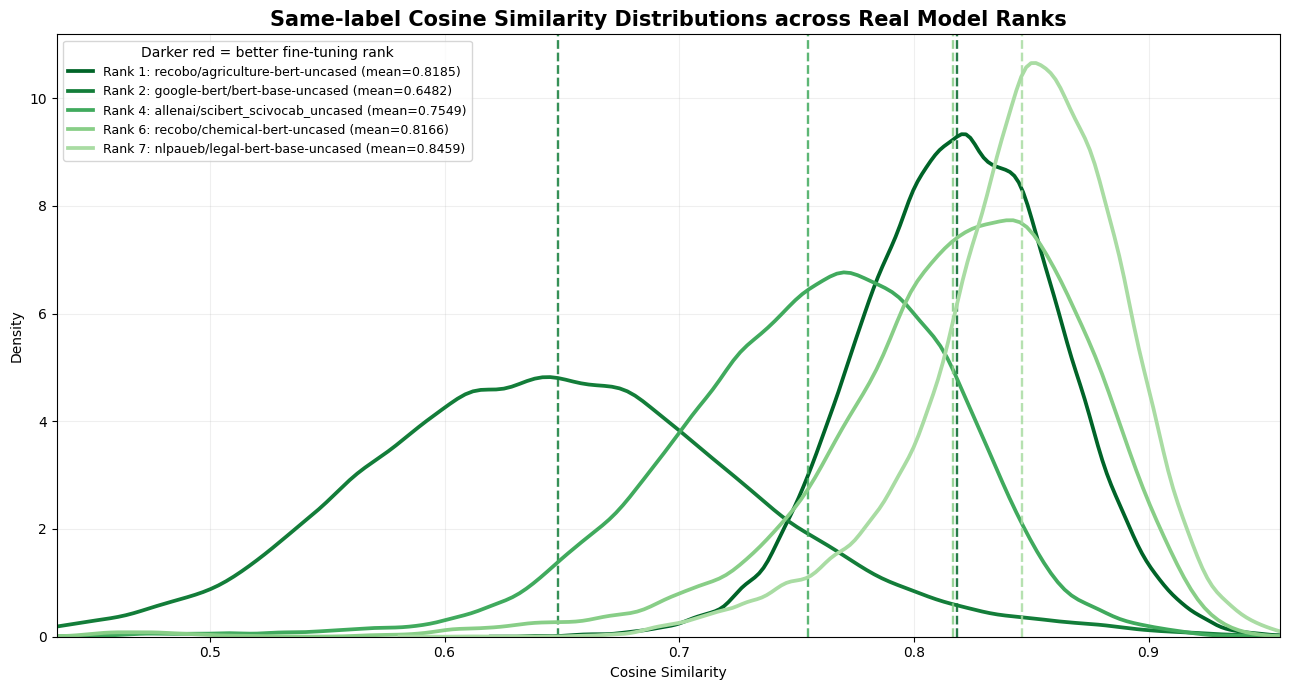

In [32]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "same_scores"
    ]

    mean_value = values[
        "same_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Same-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker red = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    "ohsumed_same_label_rank_spanning.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

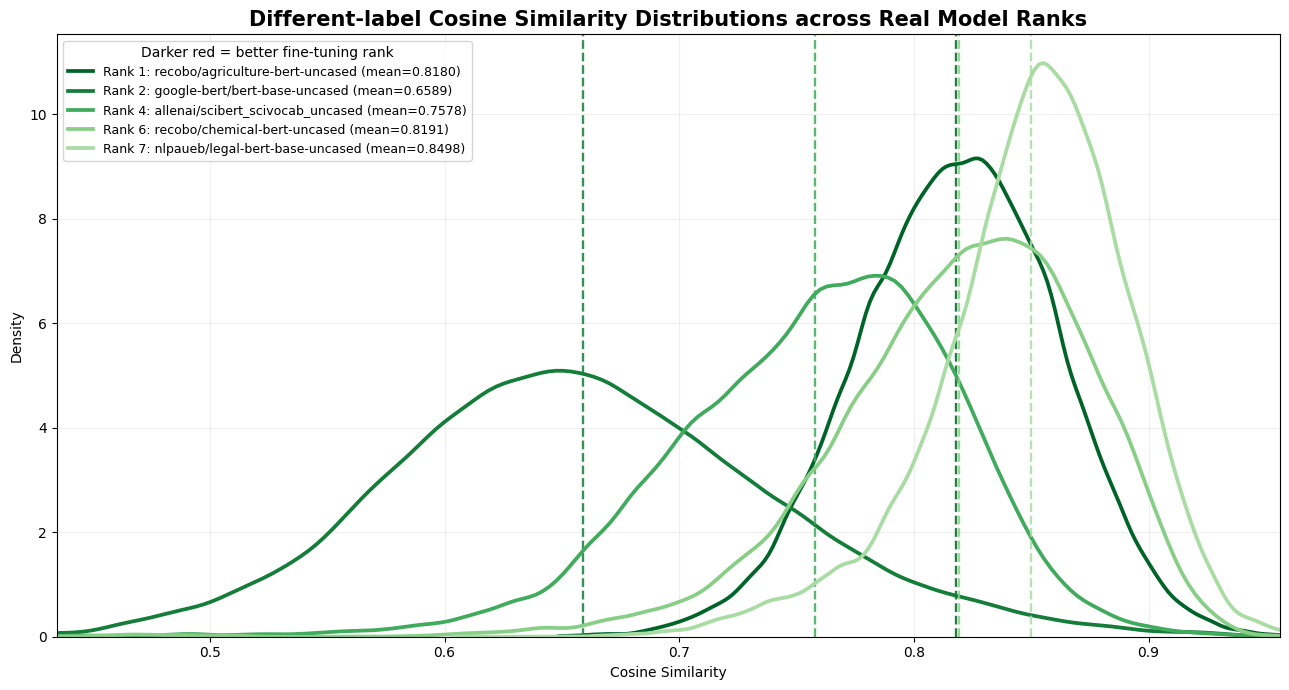

In [33]:
plt.figure(
    figsize=(13, 7)
)

for model_name in selected_models:
    values = distribution_data[
        model_name
    ]

    real_rank = values[
        "real_rank"
    ]

    scores = values[
        "diff_scores"
    ]

    mean_value = values[
        "diff_mean"
    ]

    colour = rank_colours[
        real_rank
    ]

    model_label = (
        f"Rank {real_rank}: "
        f"{model_name} "
        f"(mean={mean_value:.4f})"
    )

    sns.kdeplot(
        scores,
        color=colour,
        linewidth=2.7,
        bw_adjust=0.8,
        clip=(-1, 1),
        cut=0,
        label=model_label,
    )

    # Mean position
    plt.axvline(
        mean_value,
        color=colour,
        linestyle="--",
        linewidth=1.7,
        alpha=0.85,
    )

plt.xlim(
    display_minimum,
    display_maximum,
)

plt.xlabel(
    "Cosine Similarity"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Different-label Cosine Similarity "
    "Distributions across Real Model Ranks",
    fontsize=15,
    fontweight="bold",
)

plt.legend(
    fontsize=9,
    title=(
        "Darker red = better "
        "fine-tuning rank"
    ),
)

plt.grid(
    alpha=0.2
)

plt.tight_layout()

plt.savefig(
    (
        "ohsumed_different_label_"
        "rank_spanning.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()